# 06_03 Hypothesis Testing: Is the Effect Real or Just Noise?

**Learning objectives**
- Set up a test: **null and alternative hypotheses**, a **test statistic**, its **null distribution** and a **rejection region**.
- Define and read a **p-value** correctly, and explain the **Type I error** ($\alpha$), **Type II error** ($\beta$) and **power** ($1-\beta$).
- Carry out a **z-test for a proportion** and a **t-test for a mean**, one- and two-sided, and connect them to confidence intervals.
- Plan a study: compute **power** and the **sample size** for a target effect, and see why p-values are **uniform under the null** (the root of the multiple-testing problem).

**Prerequisites:** [06_02 Confidence intervals](06_02_confidence_intervals.ipynb), [05_02 The central limit theorem](../../module_05_sampling/notebooks/05_02_central_limit_theorem.ipynb), [02_08 Student's t, chi-square and F](../../module_02_continuous/notebooks/02_08_t_chisquare_f.ipynb).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

import math

## 2. Prerequisite recap

- A **sampling distribution** describes how a statistic varies from sample to sample (05_03); for a proportion $\hat p\approx N\big(p,\,p(1-p)/n\big)$, for a mean with unknown spread $\dfrac{\bar X-\mu}{s/\sqrt n}\sim t_{n-1}$ (06_02).
- **Tail probabilities** of the standard Normal: $P(Z>1.645)=0.05$, $P(|Z|>1.96)=0.05$.
- **Confidence intervals** collect the plausible values for a parameter (06_02).
- **Probability integral transform:** if $X$ has a continuous CDF $F$ then $F(X)\sim\text{Uniform}(0,1)$ (00_04).

## 3. Intuition and story

A new web page converts 6.2 % of visitors while the old one converted 5.0 %. Is the new page better, or did we just get a lucky sample? A **hypothesis test** answers by asking: *if there were no real difference (the null hypothesis $H_0$), how surprising would data this extreme be?* If such data would be very rare under $H_0$, we **reject** $H_0$.

It works like a court case. The null hypothesis is "innocent until proven guilty": we keep it unless the evidence is strong. Two kinds of mistake are possible and cannot both be made zero:

- **Type I error:** convicting an innocent person (rejecting a true $H_0$). We fix its probability in advance: the **significance level** $\alpha$ (often 5 %).
- **Type II error:** letting a guilty person go (failing to reject a false $H_0$), with probability $\beta$. The **power** $1-\beta$ is the chance of catching a real effect.

The p-value measures the strength of the evidence against $H_0$; the power tells us in advance whether the study is capable of finding the effect we care about.

## 4. Formal definitions

| Term | Definition |
|---|---|
| **Null hypothesis** $H_0$ | the "no effect / status quo" claim, e.g. $p=0.05$ |
| **Alternative** $H_1$ | the claim we look for: two-sided $p\ne0.05$, or one-sided $p>0.05$ |
| **Test statistic** $T$ | a number summarising the data, e.g. $z=\dfrac{\hat p-p_0}{\sqrt{p_0(1-p_0)/n}}$ |
| **Null distribution** | the distribution of $T$ if $H_0$ is true |
| **p-value** | $P(T\text{ at least as extreme as observed}\mid H_0)$ |
| **Significance level** $\alpha$ | the Type I error rate we accept; reject $H_0$ if p-value $\le\alpha$ |
| **Type II error** $\beta$ | $P(\text{do not reject}\mid H_1\text{ true})$ |
| **Power** | $1-\beta=P(\text{reject}\mid H_1\text{ true})$; depends on the effect size, $n$, $\sigma$ and $\alpha$ |
| **Effect size** | the true difference of interest, often standardised: $d=(\mu-\mu_0)/\sigma$ |

**Common tests.** $z$-test for a proportion (above); one-sample $t$-test: $t=\dfrac{\bar x-\mu_0}{s/\sqrt n}\sim t_{n-1}$; two-sided p-value $2P(T_{n-1}>|t|)$.

**Sample size for a one-sided test of $p_0$ against $p_1$** (power $1-\beta$): $n=\Big(\dfrac{z_{\alpha}\sqrt{p_0q_0}+z_{\beta}\sqrt{p_1q_1}}{p_1-p_0}\Big)^2$ with $q=1-p$; for a mean with SD $\sigma$ and difference $\delta$: $n=\big((z_{\alpha}+z_\beta)\sigma/\delta\big)^2$.

## 5. Derivations

### 5.1 The p-value is a tail area of the null distribution
For the right-sided $z$-test the p-value is $P(Z\ge z_{\rm obs}\mid H_0)=1-\Phi(z_{\rm obs})$; for the two-sided test it is $2\big(1-\Phi(|z_{\rm obs}|)\big)$. **In plain words.** It is the share of imaginary worlds in which $H_0$ is true that produce data at least as extreme as ours.

### 5.2 Type I error equals $\alpha$ by construction
Rejecting when $z\ge z_{1-\alpha}$ has probability $P(Z\ge z_{1-\alpha})=\alpha$ under $H_0$. **In plain words.** We choose the rejection region so that a true null is wrongly rejected exactly $\alpha$ of the time.

### 5.3 Power of the one-sided $z$-test for a mean
Reject when $\bar X>\mu_0+z_{1-\alpha}\sigma/\sqrt n$. If the true mean is $\mu_1=\mu_0+\delta$ then $\bar X\sim N(\mu_1,\sigma^2/n)$ and
$$\text{power}=P\Big(Z>z_{1-\alpha}-\frac{\delta\sqrt n}{\sigma}\Big)=\Phi\Big(\frac{\delta\sqrt n}\sigma-z_{1-\alpha}\Big).$$
**In plain words.** Power grows with the effect size $\delta$, with the sample size (through $\sqrt n$) and with a larger $\alpha$, and falls with noisier data. Solving for $n$ gives $n=\big((z_{1-\alpha}+z_{1-\beta})\sigma/\delta\big)^2$.

### 5.4 Under $H_0$ the p-value is Uniform(0,1)
If $T$ has a continuous null CDF $F$, the right-sided p-value is $P=1-F(T)$, and $1-F(T)\sim\text{Uniform}(0,1)$ by the probability integral transform. Hence $P(P\le\alpha)=\alpha$ for every $\alpha$. **In plain words.** If nothing is going on, p-values are equally likely to be anywhere between 0 and 1: 5 % of them fall below 0.05 *by chance*. Under $H_1$ the p-values pile up near 0.

### 5.5 Confidence interval and test are two views of one thing
A two-sided level-$\alpha$ test of $H_0:\mu=\mu_0$ rejects exactly when $\mu_0$ lies outside the $(1-\alpha)$ confidence interval. **In plain words.** The interval is the list of null values that the data cannot reject; it shows the *size* of the effect, the p-value only its *surprise*.

### 5.6 The Neyman-Pearson lemma (statement)
For two simple hypotheses the most powerful test at level $\alpha$ rejects when the **likelihood ratio** $L(\theta_1)/L(\theta_0)$ is large. The $z$ and $t$ tests are special cases. **In plain words.** The best evidence is the ratio of how well each hypothesis explains the data.

## 6. Properties and relationships

- **$\alpha$ and $\beta$ trade off:** lowering $\alpha$ (a stricter test) lowers the power for a fixed sample size; only more data reduces both.
- **Statistical versus practical significance:** with a huge $n$ even a trivial effect gives a tiny p-value; always look at the effect size and its interval.
- **Not rejecting is not accepting:** a non-significant result can simply mean low power (Example 2).
- **One-sided versus two-sided:** a one-sided test is more powerful in its direction but ignores the other; decide *before* seeing the data.
- **Testing many hypotheses** inflates the chance of at least one false positive (Example 3, 06_06); a nonparametric alternative needs fewer assumptions (06_05).
- **Link to ML and AI:** comparing two models on a test set, deciding whether a feature matters, and A/B tests of ranking changes are all hypothesis tests; Module 10 builds precision/recall on the same error types.

## 7. 2D visuals

### 7.1 The picture of $\alpha$, $\beta$ and power
Null distribution of $\hat p$ (centred at 0.05) and alternative distribution (centred at 0.06) for $n=2000$. The rejection region is to the right of the critical value; the area under $H_0$ beyond it is $\alpha$, the area under $H_1$ beyond it is the power.

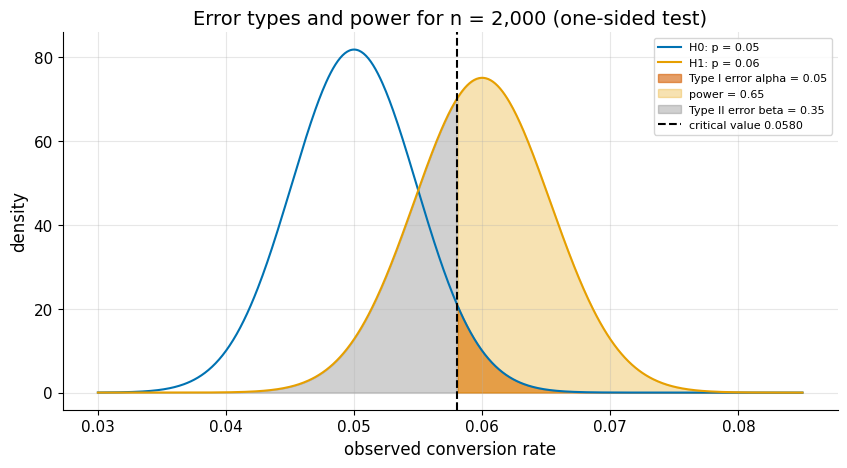

In [2]:
p0, p1, n_p = 0.05, 0.06, 2000
se0, se1 = np.sqrt(p0 * (1 - p0) / n_p), np.sqrt(p1 * (1 - p1) / n_p); crit = p0 + stats.norm.ppf(0.95) * se0
xs = np.linspace(0.03, 0.085, 600)
fig, ax = plt.subplots(figsize=(10, 4.9))
ax.plot(xs, stats.norm.pdf(xs, p0, se0), color=MAIN, label="H0: p = 0.05"); ax.plot(xs, stats.norm.pdf(xs, p1, se1), color=SIM, label="H1: p = 0.06")
ax.fill_between(xs, 0, stats.norm.pdf(xs, p0, se0), where=xs >= crit, color=HIGHLIGHT, alpha=0.6, label=f"Type I error alpha = 0.05")
ax.fill_between(xs, 0, stats.norm.pdf(xs, p1, se1), where=xs >= crit, color=SIM, alpha=0.3, label=f"power = {stats.norm.sf(crit, p1, se1):.2f}")
ax.fill_between(xs, 0, stats.norm.pdf(xs, p1, se1), where=xs < crit, color=NEUTRAL, alpha=0.3, label=f"Type II error beta = {stats.norm.cdf(crit, p1, se1):.2f}")
ax.axvline(crit, color="black", linestyle="--", label=f"critical value {crit:.4f}"); ax.set_xlabel("observed conversion rate"); ax.set_ylabel("density"); ax.set_title("Error types and power for n = 2,000 (one-sided test)"); ax.legend(fontsize=8)
plt.show()
assert abs(stats.norm.sf(crit, p1, se1) - 0.645) < 0.01

### 7.2 Power curves: effect size and sample size
The power of a one-sided $z$-test for a proportion (baseline 5 %) against the true rate, for four sample sizes. A real improvement from 5 % to 6 % is detected with 64 % power at $n=2000$, but 90 % power needs about $n=4300$.

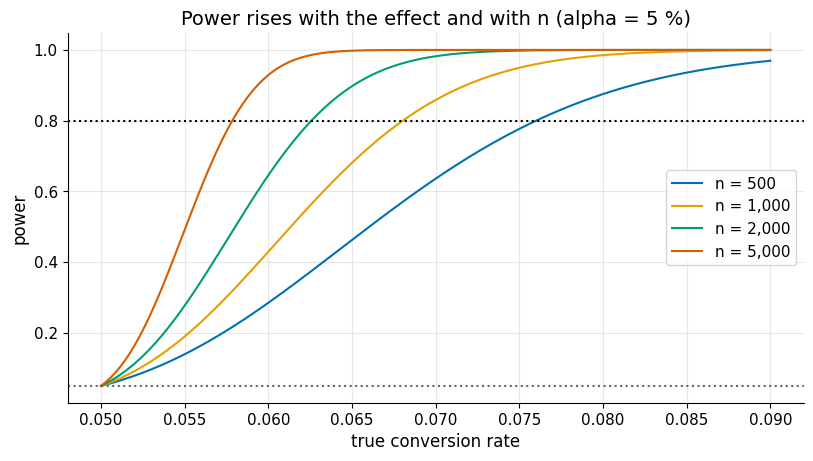

{500: 0.285, 1000: 0.429, 2000: 0.646, 5000: 0.929, 10000: 0.997} | at p = 0.05 the 'power' equals alpha: 0.05


In [3]:
p_true = np.linspace(0.05, 0.09, 200)
def power_prop(p_alt, n, p_null=0.05, alpha=0.05):
    c = p_null + stats.norm.isf(alpha) * np.sqrt(p_null * (1 - p_null) / n); return stats.norm.sf(c, p_alt, np.sqrt(p_alt * (1 - p_alt) / n))
fig, ax = plt.subplots(figsize=(9.5, 4.8))
for nn, c in zip([500, 1000, 2000, 5000], COLORS): ax.plot(p_true, power_prop(p_true, nn), color=c, label=f"n = {nn:,}")
ax.axhline(0.8, color="black", linestyle=":"); ax.axhline(0.05, color=NEUTRAL, linestyle=":"); ax.set_xlabel("true conversion rate"); ax.set_ylabel("power"); ax.set_title("Power rises with the effect and with n (alpha = 5 %)"); ax.legend()
plt.show()
print({nn: round(float(power_prop(0.06, nn)), 3) for nn in (500, 1000, 2000, 5000, 10000)}, "| at p = 0.05 the 'power' equals alpha:", round(float(power_prop(0.05, 2000)), 3))
assert abs(power_prop(0.05, 2000) - 0.05) < 1e-9

### 7.3 p-values are uniform when nothing is going on
Ten thousand two-sample $t$-tests on pure noise (both groups $N(0,1)$, $n=20$): the p-values are flat, and 5 % are below 0.05. With a real effect ($d=0.8$) they pile up near 0.

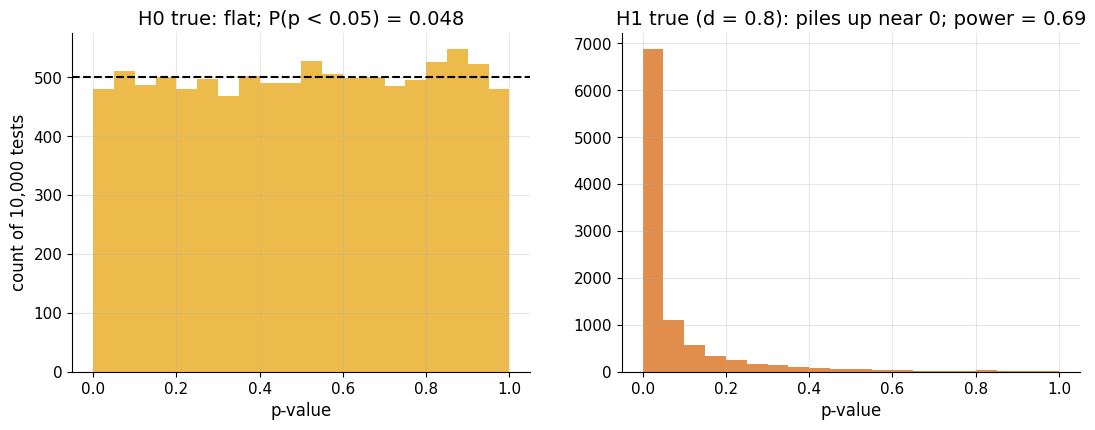

In [4]:
a0, b0 = rng.normal(size=(10_000, 20)), rng.normal(size=(10_000, 20)); pv_null = stats.ttest_ind(a0, b0, axis=1).pvalue
a1, b1 = rng.normal(0.8, 1, (10_000, 20)), rng.normal(size=(10_000, 20)); pv_alt = stats.ttest_ind(a1, b1, axis=1).pvalue
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
axes[0].hist(pv_null, bins=20, range=(0, 1), color=SIM, alpha=0.7); axes[0].axhline(500, color="black", linestyle="--"); axes[0].set_title(f"H0 true: flat; P(p < 0.05) = {np.mean(pv_null < 0.05):.3f}"); axes[0].set_xlabel("p-value"); axes[0].set_ylabel("count of 10,000 tests")
axes[1].hist(pv_alt, bins=20, range=(0, 1), color=HIGHLIGHT, alpha=0.7); axes[1].set_title(f"H1 true (d = 0.8): piles up near 0; power = {np.mean(pv_alt < 0.05):.2f}"); axes[1].set_xlabel("p-value")
plt.show()
assert abs(np.mean(pv_null < 0.05) - 0.05) < 0.008 and stats.kstest(pv_null, "uniform").pvalue > 0.001 and 0.6 < np.mean(pv_alt < 0.05) < 0.8

### 7.4 One-sided versus two-sided p-values
The same observed $z=2.46$ gives a one-sided p-value of 0.0069 and a two-sided one of 0.0138 (twice as large): the two-sided test spends its $\alpha$ on both tails.

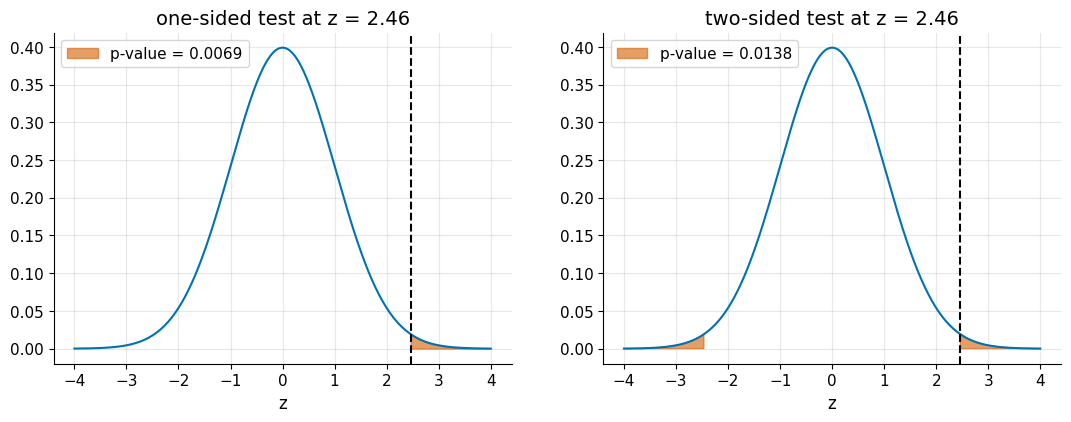

In [5]:
z_obs = 2.463; zs = np.linspace(-4, 4, 600)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
for ax, tails, title in [(axes[0], "right", "one-sided"), (axes[1], "both", "two-sided")]:
    ax.plot(zs, stats.norm.pdf(zs), color=MAIN)
    mask = zs >= z_obs if tails == "right" else (np.abs(zs) >= z_obs)
    ax.fill_between(zs, 0, stats.norm.pdf(zs), where=mask, color=HIGHLIGHT, alpha=0.6, label=f"p-value = {stats.norm.sf(z_obs) * (1 if tails == 'right' else 2):.4f}")
    ax.axvline(z_obs, color="black", linestyle="--"); ax.set_title(f"{title} test at z = 2.46"); ax.set_xlabel("z"); ax.legend()
plt.show()
assert abs(2 * stats.norm.sf(2.463) - 0.0138) < 5e-4

## 8. 3D visuals

### 8.1 Static: power over (effect size, sample size)
The power of a two-sided $z$-test ($\alpha=0.05$) as a function of the standardised effect $d=\delta/\sigma$ and the sample size $n$. The surface is an S-shaped ramp: nothing to find for tiny effects or tiny samples, certainty beyond the ridge. The contour where the surface crosses 0.8 is the usual planning target.

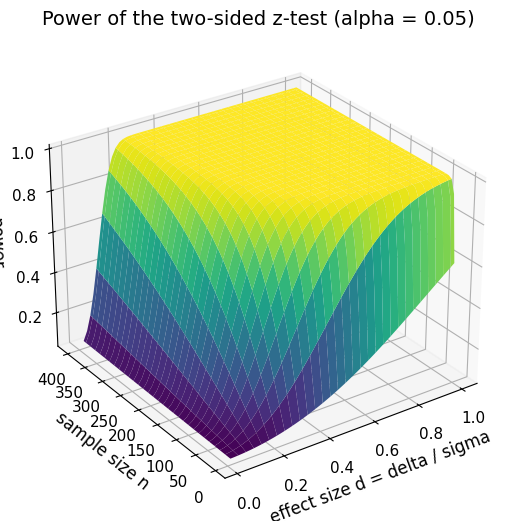

n needed for 80 % power at d = 0.5: 32 | at d = 0.2: 197


In [6]:
d_ax = np.linspace(0.02, 1.0, 60); n_ax = np.linspace(5, 400, 60)
Dg, Ng = np.meshgrid(d_ax, n_ax)
zc = stats.norm.isf(0.025); PW = stats.norm.sf(zc - Dg * np.sqrt(Ng)) + stats.norm.cdf(-zc - Dg * np.sqrt(Ng))
fig = plt.figure(figsize=(8.8, 6.2))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(Dg, Ng, PW, cmap="viridis", edgecolor="none")
ax.set_xlabel("effect size d = delta / sigma"); ax.set_ylabel("sample size n"); ax.set_zlabel("power"); ax.set_title("Power of the two-sided z-test (alpha = 0.05)"); ax.view_init(elev=28, azim=-125)
plt.show()
print("n needed for 80 % power at d = 0.5:", math.ceil(((zc + stats.norm.ppf(0.8)) / 0.5) ** 2), "| at d = 0.2:", math.ceil(((zc + stats.norm.ppf(0.8)) / 0.2) ** 2))
assert math.ceil(((zc + stats.norm.ppf(0.8)) / 0.5) ** 2) == 32

### 8.2 Interactive Plotly version of 8.1
Hover to read the power for any effect size and sample size.

In [7]:
fig = go.Figure(go.Surface(x=d_ax, y=n_ax, z=PW, colorscale="Viridis"))
fig.update_layout(title="Power of the two-sided z-test", width=760, height=560, scene=dict(xaxis_title="effect size d", yaxis_title="n", zaxis_title="power"))
fig.show()

### 8.3 Static: the sample size needed over (effect size, power)
$n=\big((z_{\alpha/2}+z_\beta)/d\big)^2$ explodes for small effects: a tiny effect needs thousands of observations, and every extra bit of power costs more.

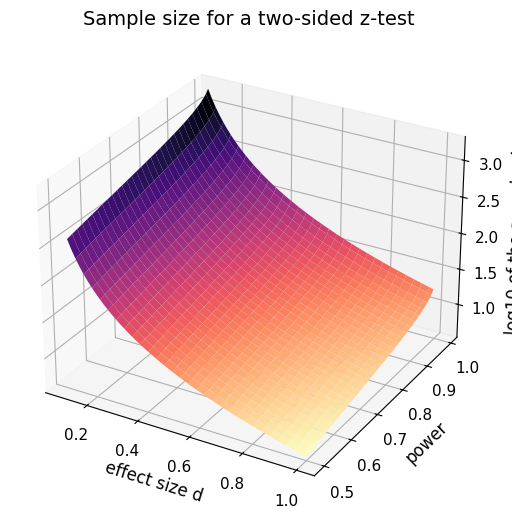

In [8]:
d_g = np.linspace(0.1, 1.0, 60); pw_g = np.linspace(0.5, 0.99, 60); Dg2, Pg2 = np.meshgrid(d_g, pw_g)
Nreq = ((zc + stats.norm.ppf(Pg2)) / Dg2) ** 2
fig = plt.figure(figsize=(8.8, 6.2))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(Dg2, Pg2, np.log10(Nreq), cmap="magma_r", edgecolor="none")
ax.set_xlabel("effect size d"); ax.set_ylabel("power"); ax.set_zlabel("log10 of the sample size"); ax.set_title("Sample size for a two-sided z-test"); ax.view_init(elev=28, azim=-60)
plt.show()

## 9. Simulation vs theory

### 9.1 Type I error and power of the $z$-test for a proportion
Simulate 400,000 experiments with $n=2000$: under $H_0$ ($p=0.05$) the one-sided test should reject about 5 % of the time; under $p=0.06$ about 64.5 % (the theoretical power).

In [9]:
k0 = rng.binomial(2000, 0.05, 400_000); k1 = rng.binomial(2000, 0.06, 400_000)
z0 = (k0 / 2000 - 0.05) / np.sqrt(0.05 * 0.95 / 2000); z1 = (k1 / 2000 - 0.05) / np.sqrt(0.05 * 0.95 / 2000)
rej0, rej1 = np.mean(z0 > stats.norm.isf(0.05)), np.mean(z1 > stats.norm.isf(0.05))
kcrit = np.floor(2000 * 0.05 + stats.norm.isf(0.05) * np.sqrt(2000 * 0.05 * 0.95)); exact_pw = stats.binom.sf(kcrit, 2000, 0.06)
print(f"rejection rate under H0 (Type I error) = {rej0:.4f} (nominal 0.05) | under p = 0.06 (power) = {rej1:.4f} (normal-approximation theory {power_prop(0.06, 2000):.4f}, exact binomial {exact_pw:.4f})")
assert abs(rej0 - 0.05) < 0.006 and abs(rej1 - exact_pw) < 0.006 and abs(rej1 - power_prop(0.06, 2000)) < 0.03

rejection rate under H0 (Type I error) = 0.0477 (nominal 0.05) | under p = 0.06 (power) = 0.6253 (normal-approximation theory 0.6457, exact binomial 0.6244)


### 9.2 The t-test: exact Type I error and the noncentral-$t$ power
For the one-sample $t$-test with $n=16$ the power at a true standardised effect $d=0.5$ is $P(|T'|>t_c)$ where $T'$ has a *noncentral* $t$ distribution with noncentrality $d\sqrt n$; simulation agrees.

In [10]:
n_t, d_t = 16, 0.5; tc = stats.t.ppf(0.975, n_t - 1); ncp = d_t * np.sqrt(n_t)
power_nct = stats.nct.sf(tc, n_t - 1, ncp) + stats.nct.cdf(-tc, n_t - 1, ncp)
x_alt = rng.normal(d_t, 1, (200_000, n_t)); x_null = rng.normal(0, 1, (200_000, n_t))
sim_power = np.mean(np.abs(stats.ttest_1samp(x_alt, 0, axis=1).statistic) > tc); sim_alpha = np.mean(np.abs(stats.ttest_1samp(x_null, 0, axis=1).statistic) > tc)
print(f"exact power {power_nct:.4f} | simulated power {sim_power:.4f} | simulated Type I error {sim_alpha:.4f} (0.05)")
assert abs(sim_power - power_nct) < 0.006 and abs(sim_alpha - 0.05) < 0.004

exact power 0.4649 | simulated power 0.4664 | simulated Type I error 0.0504 (0.05)


## 10. `scipy.stats` and NumPy cheat sheet for this lesson

In [11]:
print("z-test for a proportion by hand: z =", round((124 / 2000 - 0.05) / np.sqrt(0.05 * 0.95 / 2000), 3), "| p-value (one-sided) =", round(stats.norm.sf(2.463), 4))
print("exact binomial test: stats.binomtest(124, 2000, 0.05, alternative='greater').pvalue =", round(stats.binomtest(124, 2000, 0.05, alternative="greater").pvalue, 4))
data = rng.normal(497.2, 5.6, 16)
r = stats.ttest_1samp(data, 500); print("one-sample t-test: stats.ttest_1samp(data, 500) -> t =", round(r.statistic, 3), ", p =", round(r.pvalue, 4), ", df =", r.df, "| confidence interval:", np.round(r.confidence_interval(0.95), 2))
print("one-sided: stats.ttest_1samp(data, 500, alternative='less').pvalue =", round(stats.ttest_1samp(data, 500, alternative="less").pvalue, 4))
print("critical values: stats.norm.isf(0.05) =", round(stats.norm.isf(0.05), 4), "| stats.t.ppf(0.975, 15) =", round(stats.t.ppf(0.975, 15), 4))
print("power of the t-test with the noncentral t: stats.nct.sf(tc, df, d * sqrt(n)) ->", round(stats.nct.sf(stats.t.ppf(0.975, 15), 15, 0.5 * 4), 4), "(one tail)")
print("p-values are uniform under H0: stats.kstest(pvalues, 'uniform').pvalue")

z-test for a proportion by hand: z = 2.462 | p-value (one-sided) = 0.0069
exact binomial test: stats.binomtest(124, 2000, 0.05, alternative='greater').pvalue = 0.0095
one-sample t-test: stats.ttest_1samp(data, 500) -> t = -3.542 , p = 0.003 , df = 15 | confidence interval: [493.65 498.42]
one-sided: stats.ttest_1samp(data, 500, alternative='less').pvalue = 0.0015
critical values: stats.norm.isf(0.05) = 1.6449 | stats.t.ppf(0.975, 15) = 2.1314
power of the t-test with the noncentral t: stats.nct.sf(tc, df, d * sqrt(n)) -> 0.4648 (one tail)
p-values are uniform under H0: stats.kstest(pvalues, 'uniform').pvalue


## 11. Real-world worked examples

---
### Example 1 (main): is the new checkout page better?

**Scenario.** The current checkout page converts **5.0 %** of visitors. A redesigned page is shown to **2,000** randomly chosen visitors and **124** of them (6.2 %) convert. We test $H_0:p=0.05$ against $H_1:p>0.05$ at $\alpha=0.05$.

**Questions**
1. Compute the **test statistic** and the **p-value**. What is the decision?
2. What is the **two-sided** p-value and the corresponding confidence interval for $p$?
3. If the true conversion rate of the new page is **6 %**, what is the **power** of this test with 2,000 visitors?
4. How many visitors are needed for **80 % power** at 6 %?
5. Check the Type I error and the power by **simulation**.

### 11.1 By hand
**Q1.** $\hat p=124/2000=0.062$. Under $H_0$: $\mathrm{SE}_0=\sqrt{0.05\times0.95/2000}=0.004873$. $z=\dfrac{0.062-0.05}{0.004873}=\mathbf{2.463}$. One-sided p-value $=1-\Phi(2.463)=\mathbf{0.0069}<0.05$: **reject $H_0$**.

**Q2.** Two-sided p-value $=2\times0.0069=\mathbf{0.0138}$. The Wilson 95 % interval for $p$ is about $(0.052,\,0.073)$, which excludes 0.05, consistent with the test.

**Q3.** Critical value $\hat p_c=0.05+1.645\times0.004873=0.05802$. If $p=0.06$: $\mathrm{SE}_1=\sqrt{0.06\times0.94/2000}=0.00531$, power $=P(\hat p>0.05802)=\Phi\big(\frac{0.06-0.05802}{0.00531}\big)=\Phi(0.373)=\mathbf{0.645}$.

**Q4.** $n=\Big(\dfrac{1.645\sqrt{0.05\times0.95}+0.8416\sqrt{0.06\times0.94}}{0.01}\Big)^2=\Big(\dfrac{0.3585+0.1999}{0.01}\Big)^2=\mathbf{3{,}118}$ visitors.

In [12]:
k_c, n_c, p_null = 124, 2000, 0.05
phat = k_c / n_c; se0 = np.sqrt(p_null * (1 - p_null) / n_c); z_obs = (phat - p_null) / se0
p_one, p_two = stats.norm.sf(z_obs), 2 * stats.norm.sf(z_obs)
ci_c = stats.binomtest(k_c, n_c).proportion_ci(confidence_level=0.95, method="wilson")
crit_c = p_null + stats.norm.isf(0.05) * se0; power_c = stats.norm.sf(crit_c, 0.06, np.sqrt(0.06 * 0.94 / n_c))
n_80 = ((stats.norm.isf(0.05) * np.sqrt(0.05 * 0.95) + stats.norm.ppf(0.8) * np.sqrt(0.06 * 0.94)) / 0.01) ** 2
print(f"Q1: z = {z_obs:.3f}, one-sided p = {p_one:.4f} -> {'reject' if p_one < 0.05 else 'do not reject'} H0")
print(f"Q2: two-sided p = {p_two:.4f}; Wilson 95 % interval ({ci_c.low:.4f}, {ci_c.high:.4f})")
print(f"Q3: critical value {crit_c:.5f}; power at p = 0.06: {power_c:.3f}")
print(f"Q4: n for 80 % power: {math.ceil(n_80)}")

Q1: z = 2.462, one-sided p = 0.0069 -> reject H0
Q2: two-sided p = 0.0138; Wilson 95 % interval (0.0522, 0.0734)
Q3: critical value 0.05802; power at p = 0.06: 0.646
Q4: n for 80 % power: 3118


### 11.2 In code with `scipy`, and the asserts

In [13]:
exact_p = stats.binomtest(k_c, n_c, p_null, alternative="greater").pvalue
assert np.isclose(z_obs, 2.463, atol=2e-3) and np.isclose(p_one, 0.0069, atol=2e-4) and np.isclose(p_two, 0.0138, atol=4e-4)
assert abs(exact_p - p_one) < 0.003 and ci_c.low > 0.05 and np.isclose(power_c, 0.645, atol=0.005) and math.ceil(n_80) == 3118
assert (p_two < 0.05) == (not (ci_c.low <= 0.05 <= ci_c.high))            # test and confidence interval agree
print(f"exact binomial p-value {exact_p:.4f} (normal approximation {p_one:.4f}) | all checks passed")

exact binomial p-value 0.0095 (normal approximation 0.0069) | all checks passed


### 11.3 Verify by simulation
Run 400,000 experiments with 2,000 visitors each under $p=0.05$ (nothing changed) and under $p=0.06$ (a real improvement) and count how often the test rejects.

In [14]:
sim_g = np.random.default_rng(31)
z_a = (sim_g.binomial(2000, 0.05, 400_000) / 2000 - 0.05) / se0; z_b = (sim_g.binomial(2000, 0.06, 400_000) / 2000 - 0.05) / se0
print(f"Type I error (p = 0.05): {np.mean(z_a > 1.645):.4f} | power (p = 0.06): {np.mean(z_b > 1.645):.4f} (normal-approximation theory {power_c:.3f}) | share of experiments with z >= 2.463 under H0: {np.mean(z_a >= z_obs):.4f} (the p-value 0.0069)")
n_sim80 = math.ceil(n_80); z_c = (sim_g.binomial(n_sim80, 0.06, 300_000) / n_sim80 - 0.05) / np.sqrt(0.05 * 0.95 / n_sim80)
print(f"power with n = {n_sim80}: {np.mean(z_c > 1.645):.4f} (target 0.80)")
assert abs(np.mean(z_a > 1.645) - 0.05) < 0.006 and abs(np.mean(z_b > 1.645) - power_c) < 0.03 and abs(np.mean(z_c > 1.645) - 0.80) < 0.035

Type I error (p = 0.05): 0.0479 | power (p = 0.06): 0.6241 (normal-approximation theory 0.646) | share of experiments with z >= 2.463 under H0: 0.0096 (the p-value 0.0069)
power with n = 3118: 0.8065 (target 0.80)


### 11.4 Plots with the regions shaded

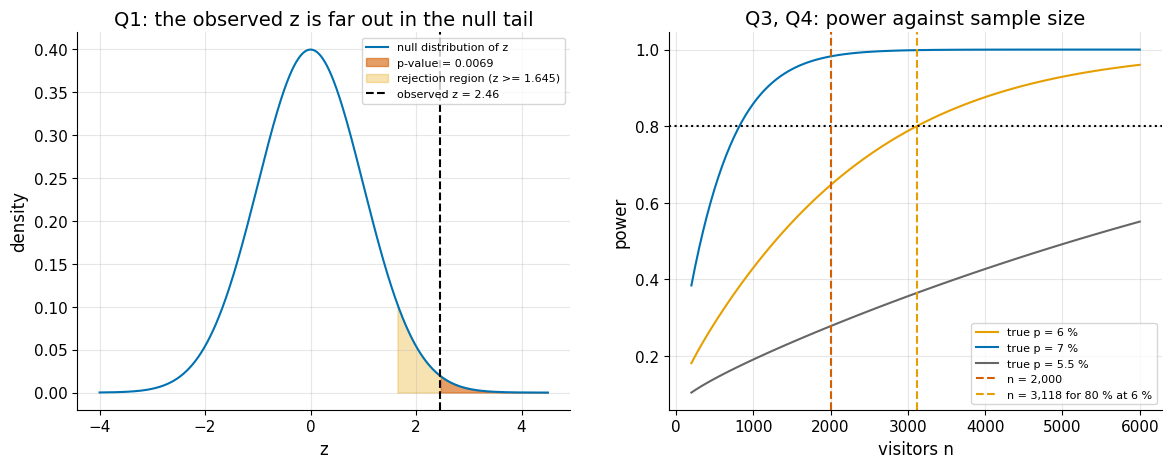

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.9))
zz = np.linspace(-4, 4.5, 600); axes[0].plot(zz, stats.norm.pdf(zz), color=MAIN, label="null distribution of z")
axes[0].fill_between(zz, 0, stats.norm.pdf(zz), where=zz >= z_obs, color=HIGHLIGHT, alpha=0.6, label=f"p-value = {p_one:.4f}"); axes[0].fill_between(zz, 0, stats.norm.pdf(zz), where=(zz >= 1.645) & (zz < z_obs), color=SIM, alpha=0.3, label="rejection region (z >= 1.645)")
axes[0].axvline(z_obs, color="black", linestyle="--", label=f"observed z = {z_obs:.2f}"); axes[0].set_xlabel("z"); axes[0].set_ylabel("density"); axes[0].set_title("Q1: the observed z is far out in the null tail"); axes[0].legend(fontsize=8)
nn = np.arange(200, 6001, 50); axes[1].plot(nn, power_prop(0.06, nn), color=SIM, label="true p = 6 %"); axes[1].plot(nn, power_prop(0.07, nn), color=MAIN, label="true p = 7 %"); axes[1].plot(nn, power_prop(0.055, nn), color=NEUTRAL, label="true p = 5.5 %")
axes[1].axhline(0.8, color="black", linestyle=":"); axes[1].axvline(2000, color=HIGHLIGHT, linestyle="--", label="n = 2,000"); axes[1].axvline(math.ceil(n_80), color=SIM, linestyle="--", label=f"n = {math.ceil(n_80):,} for 80 % at 6 %")
axes[1].set_xlabel("visitors n"); axes[1].set_ylabel("power"); axes[1].set_title("Q3, Q4: power against sample size"); axes[1].legend(fontsize=8)
plt.show()

### 11.5 Interpretation and decision (Example 1)
- The observed conversion of **6.2 %** is **2.46 standard errors** above the old rate 5 %, giving a one-sided p-value of **0.0069** (0.0095 with the exact binomial test): if the new page were no better, a result this good would occur less than once in 100 experiments. We **reject $H_0$** at the 5 % level (and at 1 %). The two-sided p-value is 0.0138 and the 95 % Wilson interval for the new page's rate is **5.2 % to 7.3 %**, excluding 5 %, so the test and the interval agree.
- **The study is only moderately powerful.** If the real rate is 6 %, the chance of detecting it with 2,000 visitors is **about 63 %** (0.646 by the normal formula, 0.624 exactly and in 400,000 simulated experiments): in 37 % of such experiments the new page would look "not significantly better". Reaching **80 % power** needs about **3,100 visitors** (3,118; simulation 80.7 %).
- The Type I error is as designed: with no real change, 4.8 % of the simulated experiments reject (nominal 5 %).
- **Decision.** Adopt the new page: the evidence is strong and the estimated lift (about +1.2 points, plausibly +0.2 to +2.3) is worth having. Keep in mind that a result that *just* crosses the threshold tends to overstate the true effect, and size the next experiment for the smaller effect you care about (a 1-point lift needs about 3,100 visitors per group, more for a two-group comparison, 06_04 and 06_07).

---
### Example 2: filling machine (a t-test that does not reject)

**Scenario.** A bottle should contain **500 g**. A sample of **16** bottles has mean **497.2 g** and standard deviation **5.6 g**. We test $H_0:\mu=500$ against $H_1:\mu\ne500$ at $\alpha=0.05$.

**Questions**
1. Compute $t$, the p-value and the decision.
2. What does the 95 % confidence interval say?
3. If the true mean were really **496 g**, what is the power of this test? How many bottles would give 90 % power?

### 11.6 By hand
**Q1.** $\mathrm{SE}=5.6/\sqrt{16}=1.4$; $t=\dfrac{497.2-500}{1.4}=\mathbf{-2.00}$ with 15 degrees of freedom. Critical value $t_{15,0.975}=2.131$; the two-sided p-value is $2P(T_{15}>2.0)=\mathbf{0.064}>0.05$: **do not reject**.

**Q2.** $497.2\pm2.131\times1.4=\mathbf{(494.2,\ 500.2)}$: 500 is *just inside* the interval, in line with the test.

**Q3.** Standardised effect $d=(496-500)/5.6=0.714$, noncentrality $d\sqrt n=2.86$; the power from the noncentral $t$ is computed below (about 0.76). For 90 % power **23 bottles** are needed (7 more).

Q1: t = -2.000, p = 0.0639 | Q2: 95 % CI (494.22, 500.18) | Q3: power at mean 496 = 0.761; bottles for 90 % power: 23


simulated power: 0.7627 (noncentral t: 0.7613)


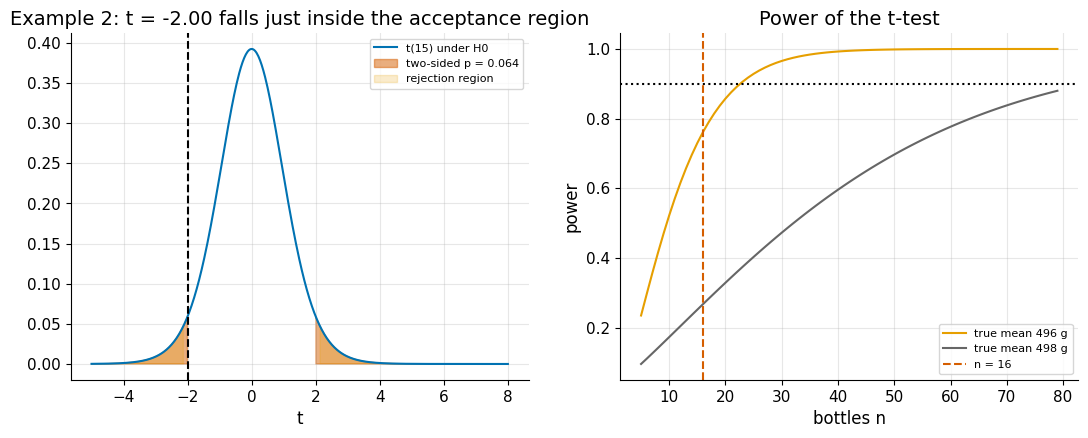

In [16]:
n2, m2, s2 = 16, 497.2, 5.6
t2 = (m2 - 500) / (s2 / np.sqrt(n2)); p2 = 2 * stats.t(n2 - 1).sf(abs(t2)); tc2 = stats.t.ppf(0.975, n2 - 1)
ci2 = (m2 - tc2 * s2 / np.sqrt(n2), m2 + tc2 * s2 / np.sqrt(n2))
def power_t(delta, sigma, n, alpha=0.05):
    tc = stats.t.ppf(1 - alpha / 2, n - 1); nc = delta / sigma * np.sqrt(n); return stats.nct.sf(tc, n - 1, nc) + stats.nct.cdf(-tc, n - 1, nc)
pw2 = power_t(4, 5.6, n2); n90 = next(nn_ for nn_ in range(5, 500) if power_t(4, 5.6, nn_) >= 0.9)
print(f"Q1: t = {t2:.3f}, p = {p2:.4f} | Q2: 95 % CI ({ci2[0]:.2f}, {ci2[1]:.2f}) | Q3: power at mean 496 = {pw2:.3f}; bottles for 90 % power: {n90}")
assert np.isclose(t2, -2.0) and abs(p2 - 0.0639) < 5e-4 and ci2[0] < 500 < ci2[1] + 0.001 and 0.74 < pw2 < 0.78 and n90 == 23
sim2 = np.random.default_rng(8).normal(496, 5.6, (200_000, 16)); rej2 = np.mean(np.abs(stats.ttest_1samp(sim2, 500, axis=1).statistic) > tc2)
print(f"simulated power: {rej2:.4f} (noncentral t: {pw2:.4f})"); assert abs(rej2 - pw2) < 0.006
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5)); tt = np.linspace(-5, 8, 500)
axes[0].plot(tt, stats.t(15).pdf(tt), color=MAIN, label="t(15) under H0"); axes[0].fill_between(tt, 0, stats.t(15).pdf(tt), where=np.abs(tt) >= abs(t2), color=HIGHLIGHT, alpha=0.5, label=f"two-sided p = {p2:.3f}"); axes[0].fill_between(tt, 0, stats.t(15).pdf(tt), where=np.abs(tt) >= tc2, color=SIM, alpha=0.2, label="rejection region")
axes[0].axvline(t2, color="black", linestyle="--"); axes[0].set_xlabel("t"); axes[0].set_title("Example 2: t = -2.00 falls just inside the acceptance region"); axes[0].legend(fontsize=8)
ns2 = np.arange(5, 80); axes[1].plot(ns2, [power_t(4, 5.6, k_) for k_ in ns2], color=SIM, label="true mean 496 g"); axes[1].plot(ns2, [power_t(2, 5.6, k_) for k_ in ns2], color=NEUTRAL, label="true mean 498 g"); axes[1].axhline(0.9, color="black", linestyle=":"); axes[1].axvline(16, color=HIGHLIGHT, linestyle="--", label="n = 16"); axes[1].set_xlabel("bottles n"); axes[1].set_ylabel("power"); axes[1].set_title("Power of the t-test"); axes[1].legend(fontsize=8)
plt.show()

### 11.7 Interpretation and decision (Example 2)
- The sample mean 497.2 g is **2.0 standard errors below 500**, but with only 16 bottles the $t$ distribution gives a two-sided p-value of **0.064**: **not significant** at 5 %. The 95 % interval (494.2, 500.2) has 500 just inside it.
- **Failing to reject is not proof that the machine is fine.** If the true mean were really 496 g (4 g too low), this test would detect it only **76 % of the time** (noncentral $t$, simulated 76.3 %); one time in four it would miss a real 4 g shortfall. With **23 bottles** the power for that shortfall rises to 90 %.
- **Decision.** Treat the result as *inconclusive, leaning towards under-filling*, and weigh the cost: if each 3 g shortfall over thousands of bottles costs customers' trust or regulatory trouble, take another 20 bottles before concluding that the machine is acceptable.

---
### Example 3: twenty tests on pure noise (why p-values need care)

**Scenario.** An analyst tests 20 unrelated metrics for a "difference" between two random groups. In truth **there is no difference in any of them**. Each test is a two-sample $t$-test at $\alpha=0.05$.

**Questions**
1. What is the probability that **at least one** of the 20 tests is "significant"?
2. How many significant results do we expect, and what is the distribution of that number?
3. How does the p-value of the *smallest* of the 20 behave?

### 11.8 By hand
**Q1.** With independent tests, $P(\text{at least one})=1-(1-0.05)^{20}=1-0.3585=\mathbf{0.642}$ (0a_03).

**Q2.** The number of significant results is $\text{Bin}(20,0.05)$: mean $1.0$, SD $0.97$, and $P(0)=0.358$, $P(1)=0.377$, $P(\ge2)=0.264$.

**Q3.** The minimum of 20 independent Uniform(0,1) p-values has the distribution $P(\min>x)=(1-x)^{20}$; its median is $1-0.5^{1/20}=\mathbf{0.034}$: the **typical best p-value is below 0.05 by chance alone**.

Q1: P(at least one significant) = 0.6415 | Q2: Binomial(20, 0.05): mean 1.00, SD 0.975, P(0) = 0.358, P(1) = 0.377, P(>= 2) = 0.264 | Q3: median of the smallest p-value = 0.0341


simulation: P(at least one significant) = 0.6443 | mean number significant 1.005 | P(0) = 0.356 | median of the smallest p-value 0.0332


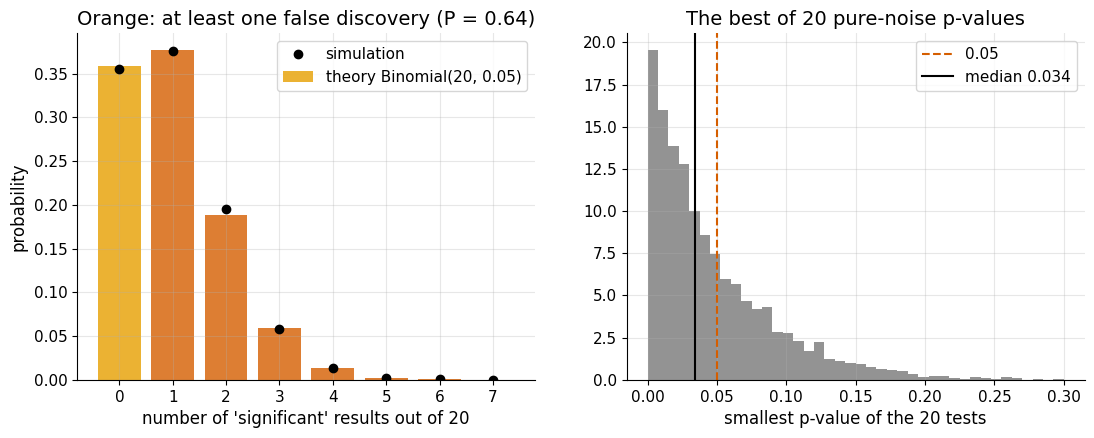

In [17]:
k_t = 20
p_any = 1 - 0.95 ** k_t; cnt = stats.binom(k_t, 0.05)
med_min = 1 - 0.5 ** (1 / k_t)
print(f"Q1: P(at least one significant) = {p_any:.4f} | Q2: Binomial(20, 0.05): mean {cnt.mean():.2f}, SD {cnt.std():.3f}, P(0) = {cnt.pmf(0):.3f}, P(1) = {cnt.pmf(1):.3f}, P(>= 2) = {cnt.sf(1):.3f} | Q3: median of the smallest p-value = {med_min:.4f}")
sim_t = np.random.default_rng(12); a = sim_t.normal(size=(6000, k_t, 25)); b = sim_t.normal(size=(6000, k_t, 25))
pv = stats.ttest_ind(a, b, axis=2).pvalue
n_sig = (pv < 0.05).sum(axis=1)
print(f"simulation: P(at least one significant) = {np.mean(n_sig >= 1):.4f} | mean number significant {n_sig.mean():.3f} | P(0) = {np.mean(n_sig == 0):.3f} | median of the smallest p-value {np.median(pv.min(axis=1)):.4f}")
assert abs(np.mean(n_sig >= 1) - p_any) < 0.02 and abs(np.median(pv.min(axis=1)) - med_min) < 0.006 and abs(n_sig.mean() - 1.0) < 0.05
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(np.arange(0, 8), cnt.pmf(np.arange(0, 8)), color=[SIM] + [HIGHLIGHT] * 7, alpha=0.8, label="theory Binomial(20, 0.05)"); axes[0].plot(np.arange(0, 8), [np.mean(n_sig == k_) for k_ in range(8)], "ko", label="simulation"); axes[0].set_xlabel("number of 'significant' results out of 20"); axes[0].set_ylabel("probability"); axes[0].set_title("Orange: at least one false discovery (P = 0.64)"); axes[0].legend()
axes[1].hist(pv.min(axis=1), bins=40, range=(0, 0.3), density=True, color=NEUTRAL, alpha=0.7); axes[1].axvline(0.05, color=HIGHLIGHT, linestyle="--", label="0.05"); axes[1].axvline(med_min, color="black", label=f"median {med_min:.3f}"); axes[1].set_xlabel("smallest p-value of the 20 tests"); axes[1].set_title("The best of 20 pure-noise p-values"); axes[1].legend()
plt.show()

### 11.9 Interpretation and decision (Example 3)
- With no real effect anywhere, the chance that **at least one of 20 tests is "significant" is 64.2 %** (simulation 64.4 %), and the expected number of false positives is exactly **1.0**: zero false positives happens only 36 % of the time, one happens 38 % of the time.
- The best (smallest) of the 20 p-values has a **median of 0.034**: the typical "most significant" result of a fishing expedition *beats the 5 % threshold by chance alone*.
- **Decision.** Decide **one primary metric in advance**; if several must be tested, control the family-wise error with Bonferroni (use $\alpha/20=0.0025$) or the false discovery rate (06_06). A single significant result among many tests should be treated as a lead to confirm, not a finding.

## 12. Where it is used

### Statistics
- **Every comparison of groups, every regression coefficient, every goodness-of-fit check** produces a test statistic and a p-value; power analysis designs experiments and clinical trials; likelihood-ratio, Wald and score tests generalise the $z$ and $t$ tests (06_01).
- **Quality control and engineering:** control charts and acceptance sampling are tests with a chosen $\alpha$ and $\beta$.

### Data science
- **A/B testing** (06_07): is the new variant better, how many users are needed, when can we stop; guard-rail metrics tested for harm.
- **Monitoring and drift detection:** a test on a feature distribution (KS, chi-square) triggers an alert; the false-alarm rate is $\alpha$ (Example 3: many monitored features means many false alarms).

### ML and AI
- **Model comparison:** is model B really better than A on the test set (a paired test on the same examples, McNemar's test), is a feature important, did fine-tuning change the behaviour; benchmark differences smaller than the noise (05_05) are not significant.
- **Detection systems** (spam, fraud, anomaly) are tests whose Type I and Type II errors are the false-positive and false-negative rates; Module 10 develops the confusion matrix, ROC and precision-recall from exactly these quantities.

## 13. Common pitfalls and misconceptions

- **The p-value is not the probability that $H_0$ is true,** nor the probability that the result is due to chance. It is $P(\text{data this extreme}\mid H_0)$.
- **"Not significant" does not mean "no effect":** the study may have low power (Example 2: a 4 g shortfall was missed with a $p=0.064$).
- **p = 0.049 and p = 0.051 are not different in kind:** the 5 % line is a convention; report the p-value and an interval.
- **Statistical significance is not importance:** with $n=10^6$ a difference of 0.01 % is "highly significant".
- **Testing many things and reporting the best** (p-hacking, Example 3) makes false discoveries almost certain; plan one primary test or correct for multiplicity (06_06).
- **Peeking:** stopping an experiment as soon as $p<0.05$ inflates the Type I error well above 5 %; fix the sample size in advance or use a sequential method (06_07).
- **Choosing one-sided after seeing the data** halves the p-value dishonestly.
- **Forgetting the assumptions:** independence of observations, the shape of the null distribution and equal variances (06_04) all matter.

## 14. Exercises

1. A coin lands heads 60 times in 100 tosses. Test $H_0:p=0.5$ (two-sided) with the $z$-test and with the exact binomial test; compare the p-values.
2. A manufacturer claims a battery lasts 20 hours. Ten batteries last on average 19.1 hours with SD 1.4. Test $H_0:\mu=20$ against $H_1:\mu<20$ at the 5 % level (one-sided $t$-test).
3. For the one-sided $z$-test of a mean ($\sigma=10$, $\mu_0=100$, $n=25$, $\alpha=0.05$) find the power when the true mean is 104, and the sample size for 90 % power.
4. Explain why lowering $\alpha$ from 0.05 to 0.01 lowers the power, and compute the effect on the power of Exercise 3.
5. 40 independent metrics are each tested at $\alpha=0.05$ with no real effect anywhere. What is the probability of at least one false positive? Which per-test $\alpha$ keeps the family-wise error at 5 % (Bonferroni)?
6. (Harder) Show by simulation that testing after every 100 observations (up to 1,000) and stopping at the first $p<0.05$ raises the Type I error rate far above 5 % when $H_0$ is true.

Solutions are at the end.

## 15. Summary table

| Item | Formula or fact | Remember |
|---|---|---|
| $z$-test, proportion | $z=\dfrac{\hat p-p_0}{\sqrt{p_0(1-p_0)/n}}$ | one-sided p $=1-\Phi(z)$ |
| $t$-test, mean | $t=\dfrac{\bar x-\mu_0}{s/\sqrt n}$, $df=n-1$ | two-sided p $=2P(T>\lvert t\rvert)$ |
| Type I error | $\alpha$ | chosen in advance |
| Power | $1-\beta=\Phi\big(\frac{\delta\sqrt n}\sigma-z_{1-\alpha}\big)$ | grows with $\delta$, $n$, $\alpha$ |
| Sample size | $n=\big((z_\alpha+z_\beta)\sigma/\delta\big)^2$ | quadruple $n$ to halve $\delta$ |
| p-value under $H_0$ | Uniform(0,1) | 5 % below 0.05 by chance |
| Many tests | $1-(1-\alpha)^m$ | Bonferroni: $\alpha/m$ |
| `scipy` | `ttest_1samp`, `binomtest`, `nct` | `kstest(p, 'uniform')` |

## Solutions

In [18]:
z1 = (0.60 - 0.5) / np.sqrt(0.25 / 100); print(f"1: z = {z1:.2f}, p (normal) = {2 * stats.norm.sf(z1):.4f}, p (exact binomial) = {stats.binomtest(60, 100, 0.5).pvalue:.4f}, with continuity correction z = {(0.595 - 0.5) / 0.05:.2f} -> p = {2 * stats.norm.sf(1.9):.4f}")
t2s = (19.1 - 20) / (1.4 / np.sqrt(10)); print(f"2: t = {t2s:.3f}, one-sided p = {stats.t(9).cdf(t2s):.4f} -> {'reject' if stats.t(9).cdf(t2s) < 0.05 else 'do not reject'} H0 at 5 %")
pw3 = stats.norm.cdf(4 * 5 / 10 - stats.norm.isf(0.05)); n90_3 = math.ceil(((stats.norm.isf(0.05) + stats.norm.ppf(0.9)) * 10 / 4) ** 2); print(f"3: power = {pw3:.4f}; n for 90 % power = {n90_3}")
pw4 = stats.norm.cdf(4 * 5 / 10 - stats.norm.isf(0.01)); print(f"4: with alpha = 0.01 the power falls from {pw3:.3f} to {pw4:.3f} (the critical value moves right, so fewer true effects cross it)")
print(f"5: P(at least one false positive in 40 tests) = {1 - 0.95 ** 40:.4f}; Bonferroni alpha = 0.05 / 40 = {0.05 / 40:.5f}")
g6 = np.random.default_rng(6); rej = 0; reps = 4000
for _ in range(reps):
    x = g6.normal(size=1000); stop = False
    for m in range(100, 1001, 100):
        z = x[:m].mean() * np.sqrt(m)
        if abs(z) > 1.96: stop = True; break
    rej += stop
print(f"6: Type I error with 10 interim looks = {rej / reps:.3f} (nominal 0.05)")
assert abs(pw3 - 0.639) < 0.002 and n90_3 == 54 and rej / reps > 0.15

1: z = 2.00, p (normal) = 0.0455, p (exact binomial) = 0.0569, with continuity correction z = 1.90 -> p = 0.0574
2: t = -2.033, one-sided p = 0.0363 -> reject H0 at 5 %
3: power = 0.6388; n for 90 % power = 54
4: with alpha = 0.01 the power falls from 0.639 to 0.372 (the critical value moves right, so fewer true effects cross it)
5: P(at least one false positive in 40 tests) = 0.8715; Bonferroni alpha = 0.05 / 40 = 0.00125


6: Type I error with 10 interim looks = 0.190 (nominal 0.05)


**1.** $z=\dfrac{0.60-0.50}{0.05}=2.00$, normal two-sided p $=\mathbf{0.0455}$; the exact binomial test gives **0.0569**, and the normal approximation with continuity correction ($z=1.90$) gives 0.0574. Right at the 5 % line the approximation and the exact test **disagree on the decision** (reject versus do not reject): use the exact test for small counts.

**2.** $t=\dfrac{19.1-20}{1.4/\sqrt{10}}=\mathbf{-2.033}$, one-sided p $=0.0363<0.05$: **reject** $H_0$; there is evidence that the mean life is below 20 hours.

**3.** Power $=\Phi\big(\frac{4\times5}{10}-1.645\big)=\Phi(0.355)=\mathbf{0.639}$; for 90 % power $n=\big((1.645+1.282)\times10/4\big)^2=\mathbf{54}$ (more than twice the 25 used).

**4.** With $\alpha=0.01$ the critical value moves to 2.326 and the power falls from 0.639 to **0.372**: demanding a stricter standard of evidence makes real effects of the same size harder to detect, unless $n$ grows.

**5.** $P(\text{at least one})=1-0.95^{40}=\mathbf{0.8715}$; Bonferroni uses $0.05/40=\mathbf{0.00125}$ per test.

**6.** Testing at 10 interim looks and stopping at the first $p<0.05$ gives a Type I error of **about 19 %**, nearly four times the nominal 5 %: peeking inflates false positives.